# 02 Evaluation (Cross-Validation and Grid Search)

* `GRID_SEARCH = False`: one cross-validation of the hyperparameters below (every value must be a
  scalar or a one-element list).
* `GRID_SEARCH = True`: any hyperparameter may be a list; every combination is cross-validated.

Every (candidate, fold) result is written to `outputs/evaluation_<timestamp>/` as soon as it is
done. If the session dies, set `RESUME_FROM` to that folder and run all cells again: finished
work is skipped, and the data is re-read from the folder rather than re-pulled.

The best candidate's out-of-fold predictions are exported in the ensemble's format to
`outputs/evaluation_<timestamp>/best/`. Bucket tables and plots can be re-run with a different
`BUCKET_WIDTH` at any time without re-fitting.

In [0]:
# ---- MLflow -------------------------------------------------------------------
USE_MLFLOW = True                     # False = no tracking at all
MLFLOW_EXPERIMENT = "/Users/patrick.white@vallen.com/nb-classifier"     # None = this notebook's experiment; or e.g. "/Users/patrick.white@vallen.com/nb-classifier"

# ---- evaluation ---------------------------------------------------------------
GRID_SEARCH = True                    # True: lists below are expanded into every combination
CV_TYPE = "oof"                       # "oof" (k-fold out-of-fold) | "repeated_holdout"
N_FOLDS = 3                           # oof: must match the NN repo for the ensemble
FOLD_METHOD = "id_hash"               # oof: "id_hash" (matches the NN repo) | "stratified"
FOLD_KEY_COL = "ID"                   # oof id_hash: column whose value decides the fold
FOLD_SEED = 0                         # oof: must match the NN repo for the ensemble
N_REPEATS = 5                         # repeated_holdout: number of random splits
TEST_SIZE = 0.2                       # repeated_holdout: share of rows held out each time
HOLDOUT_SEED = 42                     # repeated_holdout
SELECTION_METRIC = "L4 Accuracy"      # how the best candidate is chosen ("L1 Accuracy" ... "L4 Accuracy")
RESUME_FROM = None                    # e.g. "evaluation_20261016_143000" to continue an interrupted run

In [0]:
# ---- prepared data ------------------------------------------------------------
PREPARED_DATA = None                  # a data/<timestamp> folder from notebook 01 ("latest" = newest);
                                      # None = pull and clean below with the settings in this cell

# ---- data source (RAW_DATA_FILE supersedes SQL_QUERY) -----------------------
RAW_DATA_FILE = None                  # e.g. "data/my_extract.txt"; read with dtype=str
RAW_DATA_DELIMITER = "|"              # delimiter of RAW_DATA_FILE
RAW_DATA_QUOTED = True                # False if RAW_DATA_FILE uses no quoting and descriptions may start with "
SQL_QUERY = "labeled_items"          # a file in data/queries/ (name without .sql); may be None only if RAW_DATA_FILE is set

# ---- items to exclude ---------------------------------------------------------
BLACKLIST_FILE = None                 # e.g. "data/blacklists/blacklist.txt" (one column)
BLACKLIST_COL = "Vallen ID"           # data column the blacklist values are matched against
BLACKLIST_HAS_HEADER = True           # first line of the blacklist file is a header

# ---- cleaning -----------------------------------------------------------------
CLEANING_METHOD = "cleaning_method_20261015"   # a folder in cleaning/ (code, term lists, settings in method.yaml)
APPEND_FIELDS = {}                    # e.g. {"Global Vendno": "VEND", "Prodline": "PLINE"} -> VEND_<value> tokens
APPEND_NULLS_AS_NONE = True           # True: null field -> VEND_None;  False: no marker for that row

# ---- columns ------------------------------------------------------------------
TEXT_COL = "FullDesc"                 # raw description field to clean
CLEANED_COL = "CleanDesc"             # header for the cleaned description
LEVEL_COLUMNS = ["Level 1 ID", "Level 2 ID", "Level 3 ID", "Level 4 ID"]      # labels the model learns
NAME_COLUMNS = ["Level 1 Name", "Level 2 Name", "Level 3 Name", "Level 4 Name"]  # carried for readability
ID_COLS = ["ID", "Vallen ID"]         # identifiers carried into every output ("ID" is the ensemble join key)

In [0]:
# ==== HYPERPARAMETERS ==========================================================
# Every hyperparameter is listed. With GRID_SEARCH = True give lists, e.g. "alpha": [0.001, 0.01].
# Tuples are single values (ngram_range=(1, 2)); write a list of tuples to search, e.g. [(1, 1), (1, 2)].

# vectorizer_kind      "tfidf" or "count"
# max_features         vocabulary cap (None = keep every feature that passes min_df/max_df)
# ngram_range          (min_n, max_n) as a TUPLE, e.g. (1, 2) = unigrams + bigrams
# min_df               ignore features in fewer documents than this (int) or proportion (float < 1)
# max_df               ignore features in more documents than this proportion (float) or count (int)
# stop_words           "english" or None
# sublinear_tf         tfidf only: use 1 + log(tf)
# binary               all non-zero counts set to 1 (before idf for tfidf)
# norm                 tfidf only: "l2", "l1" or None
# use_idf              tfidf only: inverse-document-frequency weighting
# ordered_bigrams      False = "A B" and "B A" are the same bigram (needs 2 in ngram_range)
# token_pattern        "whitespace" = each cleaned word is a token (<SIZE>IN stays whole);
#                      "sklearn" = sklearn default (2+ word characters: <SIZE>IN -> SIZE, IN); or a regex
# alpha                additive (Laplace/Lidstone) smoothing, > 0
# fit_prior            learn class priors (True) or use uniform priors (False)
# prediction_mode      "independent" | "conditional" | "flattened"  (see README)
# rare_path_threshold  drop training rows whose category path occurs fewer times than this

HYPERPARAMETERS = {
    "vectorizer_kind":     ["tfidf"],               # tfidf, count
    "max_features":        [None, 150000, 200000, 250000],
    "ngram_range":         [(1, 2)],
    "min_df":              [2],
    "max_df":              [0.95],
    "stop_words":          ["english"],
    "sublinear_tf":        [True],
    "binary":              [True],
    "norm":                ["l2"],
    "use_idf":             [False],
    "ordered_bigrams":     [True],
    "token_pattern":       ["whitespace"],
    "alpha":               [0.001],
    "fit_prior":           [True],
    "prediction_mode":     ["independent"],         # independent, conditional, flattened
    "rare_path_threshold": [5],
}

In [0]:
# ---- setup (no settings below this line need changing) ----------------------
import sys
from pathlib import Path

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

import pandas as pd
from nbclassifier import config, crossval, data, evaluation, paths
from nbclassifier.tracking import Tracker

candidates = config.expand_grid(HYPERPARAMETERS, GRID_SEARCH)
cv = config.CVSettings(cv_type=CV_TYPE, n_folds=N_FOLDS, fold_method=FOLD_METHOD, fold_key_col=FOLD_KEY_COL,
                       fold_seed=FOLD_SEED, n_repeats=N_REPEATS, test_size=TEST_SIZE, holdout_seed=HOLDOUT_SEED)
tracker = Tracker(USE_MLFLOW, MLFLOW_EXPERIMENT, run_name=f"02_evaluation_{paths.timestamp()}",
                  tags={"notebook": "02_evaluation", "grid_search": GRID_SEARCH})
print(f"{len(candidates)} candidate(s) x {N_FOLDS if CV_TYPE == 'oof' else N_REPEATS} splits")
config.params_table(candidates)

2026/10/19 15:32:22 INFO mlflow.tracking.fluent: Experiment with name '/Users/patrick.white@vallen.com/nb-classifier' does not exist. Creating a new experiment.
{"ts": "2026-10-19 15:32:34.941", "level": "WARNING", "logger": "pyspark.sql.connect.logging", "msg": "Effective usage policy for this session is cct.Chpub3RlYm9va3MvMzA5ODM0NTk5Njk4MjI5NhABIAEyJDAxYTE1NGFjLWEyYmItN2ZkOC04ZDFhLThkNTUzN2VkMWM5ZjokMWExMjViOTEtODRjYi0zY2Q5LTgxNDQtZGUyNzNhNzY3MTMzSgwIyuDY1gYQwIHOywFQAVgBYAFo6KvZ19a7sgGIAQA=.", "context": {}}
{"ts": "2026-10-19 15:32:34.941", "level": "WARNING", "logger": "pyspark.sql.connect.logging", "msg": "Effective usage policy for this session is cct.Chpub3RlYm9va3MvMzA5ODM0NTk5Njk4MjI5NhABIAEyJDAxYTE1NGFjLWEyYmItN2ZkOC04ZDFhLThkNTUzN2VkMWM5ZjokMWExMjViOTEtODRjYi0zY2Q5LTgxNDQtZGUyNzNhNzY3MTMzSgwIyuDY1gYQwIHOywFQAVgBYAFo6KvZ19a7sgGIAQA=.", "context": {}}
{"ts": "2026-10-19 15:32:34.941", "level": "WARNING", "logger": "pyspark.sql.connect.logging", "msg": "Effective usage policy

[mlflow] run 4f2c877452ec4fffa7ca5745a07610d4 (02_evaluation_20261019_153218)
4 candidate(s) x 3 splits


,vectorizer_kind,max_features,ngram_range,min_df,max_df,stop_words,sublinear_tf,binary,norm,use_idf,ordered_bigrams,token_pattern,alpha,fit_prior,prediction_mode,rare_path_threshold
candidate,,,,,,,,,,,,,,,,
0,tfidf,NaN,"(1, 2)",2,0.95,english,True,True,l2,False,True,whitespace,0.001,True,independent,5
1,tfidf,150000.0,"(1, 2)",2,0.95,english,True,True,l2,False,True,whitespace,0.001,True,independent,5
2,tfidf,200000.0,"(1, 2)",2,0.95,english,True,True,l2,False,True,whitespace,0.001,True,independent,5
3,tfidf,250000.0,"(1, 2)",2,0.95,english,True,True,l2,False,True,whitespace,0.001,True,independent,5


## Data

In [0]:
if RESUME_FROM:
    prepared = None
    print(f"Resuming {RESUME_FROM}: the data saved in that folder is used; data settings above are ignored.")
elif PREPARED_DATA:
    prepared = data.load_dataset(PREPARED_DATA)
    print(f"loaded {prepared.metadata['loaded_from']} (cleaning method {prepared.cleaner.method_name!r})")
    prepared = data.blacklist_prepared(prepared, BLACKLIST_FILE, BLACKLIST_COL, BLACKLIST_HAS_HEADER)
    data.print_summary(prepared.metadata["row_counts"], prepared.metadata["ngram_stats"])
    TEXT_COL, CLEANED_COL = prepared.metadata["text_col"], prepared.metadata["cleaned_col"]
else:
    prepared = data.prepare_dataset(
        raw_data_file=RAW_DATA_FILE, sql_query=SQL_QUERY, delimiter=RAW_DATA_DELIMITER,
        blacklist_file=BLACKLIST_FILE, blacklist_col=BLACKLIST_COL, blacklist_has_header=BLACKLIST_HAS_HEADER,
        cleaning_method=CLEANING_METHOD,
        append_fields=APPEND_FIELDS, append_nulls_as_none=APPEND_NULLS_AS_NONE,
        text_col=TEXT_COL, cleaned_col=CLEANED_COL, level_columns=LEVEL_COLUMNS,
        raw_data_quoted=RAW_DATA_QUOTED, spark=globals().get("spark"),
    )
if prepared is not None and data.duplicate_count(prepared.df, FOLD_KEY_COL):
    print(f"note: {data.duplicate_count(prepared.df, FOLD_KEY_COL):,} rows share a {FOLD_KEY_COL!r} value "
          "(they always land in the same fold)")

raw data rows      :      814,087
rows dropped       :        2,867
cleaned data rows  :      811,220
unique tokens      :       33,156
unique bigrams     :      472,937
tokens + bigrams   :      506,093


## Cross-validation / grid search

In [0]:
if RESUME_FROM:
    ev = crossval.Evaluation.open(RESUME_FROM, candidates=candidates, cv=cv)
else:
    columns = crossval.Columns(text_col=TEXT_COL, cleaned_col=CLEANED_COL, level_columns=LEVEL_COLUMNS,
                               name_columns=NAME_COLUMNS, id_cols=ID_COLS)
    ev = crossval.Evaluation.create(prepared, candidates, cv, columns, grid_search=GRID_SEARCH)
    del prepared  # the evaluation keeps its own copy on disk
LEVEL_COLUMNS = ev.cols.level_columns  # (as saved in the evaluation folder, relevant when resuming)
print("evaluation folder:", ev.folder)

results = ev.run(tracker=tracker)

[evaluation] created /Workspace/Users/patrick.white@vallen.com/Category Classification/New NB Repo/outputs/evaluation_20261019_153413
evaluation folder: /Workspace/Users/patrick.white@vallen.com/Category Classification/New NB Repo/outputs/evaluation_20261019_153413

[group] candidates [0] | rare_path_threshold=5
  fold 0: training on 538,446 rows / 3,360 paths (2,426 rare-path rows dropped); predicting 270,348 held-out rows
  [1/12] candidate 0 fold 0: L1=0.9356 L2=0.9138 L3=0.8739 L4=0.8093  (fit 12s, predict 70s, 181,406 features, 3,360 paths)
  fold 1: training on 537,903 rows / 3,329 paths (2,517 rare-path rows dropped); predicting 270,800 held-out rows
  [2/12] candidate 0 fold 1: L1=0.9357 L2=0.9138 L3=0.8736 L4=0.8081  (fit 12s, predict 74s, 182,070 features, 3,329 paths)
  fold 2: training on 538,701 rows / 3,364 paths (2,447 rare-path rows dropped); predicting 270,072 held-out rows
  [3/12] candidate 0 fold 2: L1=0.9353 L2=0.9138 L3=0.8743 L4=0.8100  (fit 12s, predict 58s, 181

## Results

In [0]:
acc_cols = [c for c in results.columns if c.endswith("Accuracy")]
best_id, best_hp, best_row = ev.best(SELECTION_METRIC)

if ev.grid_search:
    show = results.sort_values(SELECTION_METRIC, ascending=False)
    varying = [c for c in show.columns if c in best_hp.to_dict() and show[c].astype(str).nunique() > 1]
    display(show[varying + acc_cols + [c + " std" for c in acc_cols] + ["splits_done"]])
    print(f"best candidate: {best_id}  ({SELECTION_METRIC} = {best_row[SELECTION_METRIC]:.4f})")
    print("\nbest hyperparameters (paste into notebook 03):")
else:
    print("hyperparameters:")
print("HYPERPARAMETERS = {")
for k, v in best_hp.to_dict().items():
    v = tuple(v) if k == "ngram_range" else v
    print(f"    {k!r:<22}: {v!r},")
print("}")

print("\nheadline accuracy by level (best candidate):")
display(ev.headline(best_id))

tracker.log_params({"best_candidate": best_id, **{f"best.{k}": v for k, v in best_hp.to_dict().items()}})
tracker.log_metrics({f"best {c}": best_row[c] for c in acc_cols})

max_features,L1 Accuracy,L2 Accuracy,L3 Accuracy,L4 Accuracy,L1 Accuracy std,L2 Accuracy std,L3 Accuracy std,L4 Accuracy std,splits_done
null,0.9355191809163874,0.9138113097756732,0.8739284795133061,0.8091229452883821,2.0814760147537287E-4,1.6383126280829058E-5,3.59098244393908E-4,9.736511403783672E-4,3
200000.0,0.9355191809163874,0.9138113097756732,0.8739284795133061,0.8091229452883821,2.0814760147537287E-4,1.6383126280829058E-5,3.59098244393908E-4,9.736511403783672E-4,3
250000.0,0.9355191809163874,0.9138113097756732,0.8739284795133061,0.8091229452883821,2.0814760147537287E-4,1.6383126280829058E-5,3.59098244393908E-4,9.736511403783672E-4,3
150000.0,0.9347389912251955,0.9128880869061824,0.8726736337867336,0.8072529683721216,1.634391529699643E-4,1.01877356467151E-4,4.233255572427197E-4,0.0010244153331557188,3


best candidate: 0  (L4 Accuracy = 0.8091)

best hyperparameters (paste into notebook 03):
HYPERPARAMETERS = {
    'vectorizer_kind'     : 'tfidf',
    'max_features'        : None,
    'ngram_range'         : (1, 2),
    'min_df'              : 2,
    'max_df'              : 0.95,
    'stop_words'          : 'english',
    'sublinear_tf'        : True,
    'binary'              : True,
    'norm'                : 'l2',
    'use_idf'             : False,
    'ordered_bigrams'     : True,
    'token_pattern'       : 'whitespace',
    'alpha'               : 0.001,
    'fit_prior'           : True,
    'prediction_mode'     : 'independent',
    'rare_path_threshold' : 5,
}

headline accuracy by level (best candidate):


L1 Accuracy,L2 Accuracy,L3 Accuracy,L4 Accuracy
0.9356163167473035,0.9138221847396689,0.8739254590379807,0.8092717534437096
0.9356610044313146,0.9137924667651404,0.8735709010339734,0.8080834564254062
0.9352802215705441,0.9138192778222104,0.8742890784679641,0.8100136259960307
0.9355193412391213,0.9138112965656665,0.873928157589803,0.8091220630655063
2.0814760147538583E-4,1.6383126280835807E-5,3.590982443938799E-4,9.736511403783588E-4


In [0]:
# Export the best candidate's out-of-fold predictions (ensemble input) and load them for the plots below
export_path = ev.export(best_id)
pred = ev.predictions(best_id, with_text=False)
tracker.log_artifact(export_path.with_suffix(".json"), "best")
pred.head()

[export] 811,220 rows -> /Workspace/Users/patrick.white@vallen.com/Category Classification/New NB Repo/outputs/evaluation_20261019_153413/best/oof_predictions.csv


,ID,Vallen ID,_row,fold,Actual Level 1 ID,Actual Level 2 ID,Actual Level 3 ID,Actual Level 4 ID,Predicted Level 1 ID,Predicted Level 2 ID,Predicted Level 3 ID,Predicted Level 4 ID,L1 Confidence,L2 Confidence,L3 Confidence,L4 Confidence,L1 Margin,L2 Margin,L3 Margin,L4 Margin,n_tokens,n_known,oov_rate
0,IACF1JY0BD2N,01058203068,4,0,L1-12800755,L2-12800757,L3-12800775,L4-13322418,L1-12800755,L2-12800761,L3-12800782,L4-12800842,0.103701,0.103688,0.103688,0.103075,0.103465,0.103501,0.103501,0.102463,4,4,0.0
1,IF3J3TL50LJS,01181214610,7,0,L1-12783670,L2-12783671,L3-12783674,L4-12784258,L1-12783670,L2-12783671,L3-12783674,L4-12784258,0.975223,0.975223,0.975223,0.975080,0.975223,0.975223,0.975223,0.974947,6,6,0.0
2,I8IGS00YH2TX,01238207718,11,0,L1-12783670,L2-12783680,L3-12783681,L4-12784237,L1-12782908,L2-12782914,L3-12782976,L4-12783401,0.000410,0.000269,0.000193,0.000142,0.000388,0.000129,0.000055,0.000004,2,2,0.0
3,I8IGSHSEHXVZ,01238210028,14,0,L1-12783670,L2-12783671,L3-12783674,L4-12784259,L1-12783670,L2-12783671,L3-12783674,L4-12784259,1.000000,1.000000,1.000000,0.995922,1.000000,1.000000,1.000000,0.991896,7,7,0.0
4,I8HGVYHDIETI,01238210321,15,0,L1-12783670,L2-12783671,L3-12783675,L4-13482887,L1-12783670,L2-12783671,L3-12783674,L4-12784259,0.999933,0.999933,0.999933,0.974358,0.999933,0.999933,0.999933,0.948846,7,7,0.0


## Results by confidence bucket (best candidate)

Change `BUCKET_WIDTH` and re-run the cells below; no re-fitting is needed.

In [0]:
BUCKET_WIDTH = 0.05
TARGET_ACCURACY = 0.95                # dashed lines: target accuracy and the coverage that achieves it
SPLIT_COL = ev.split_col
PLOT_DIR = ev.folder / "best" / "plots"

buckets = evaluation.bucket_tables(pred, LEVEL_COLUMNS, width=BUCKET_WIDTH)
buckets.to_csv(ev.folder / "best" / f"buckets_width_{BUCKET_WIDTH}.csv", index=False)
tracker.log_table(buckets, f"best/buckets_width_{BUCKET_WIDTH}.csv")
ROUND_COLS = ["lower", "upper", "share_of_items", "accuracy", "mean_confidence",
              "cumulative_coverage", "cumulative_accuracy"]
display(buckets[buckets["level"] == f"L{len(LEVEL_COLUMNS)}"].round({c: 3 for c in ROUND_COLS}))

level,bucket,lower,upper,n_items,share_of_items,accuracy,mean_confidence,cumulative_coverage,cumulative_accuracy
L4,0.00-0.05,0.0,0.05,47234,0.058,0.234,0.015,1.0,0.809
L4,0.05-0.10,0.05,0.1,16253,0.02,0.375,0.074,0.942,0.845
L4,0.10-0.15,0.1,0.15,11925,0.015,0.378,0.125,0.922,0.855
L4,0.15-0.20,0.15,0.2,11513,0.014,0.416,0.175,0.907,0.863
L4,0.20-0.25,0.2,0.25,10731,0.013,0.451,0.224,0.893,0.87
L4,0.25-0.30,0.25,0.3,9253,0.011,0.469,0.275,0.88,0.876
L4,0.30-0.35,0.3,0.35,9996,0.012,0.512,0.325,0.868,0.881
L4,0.35-0.40,0.35,0.4,9269,0.011,0.521,0.374,0.856,0.887
L4,0.40-0.45,0.4,0.45,8933,0.011,0.542,0.425,0.844,0.892
L4,0.45-0.50,0.45,0.5,10143,0.013,0.558,0.476,0.833,0.896


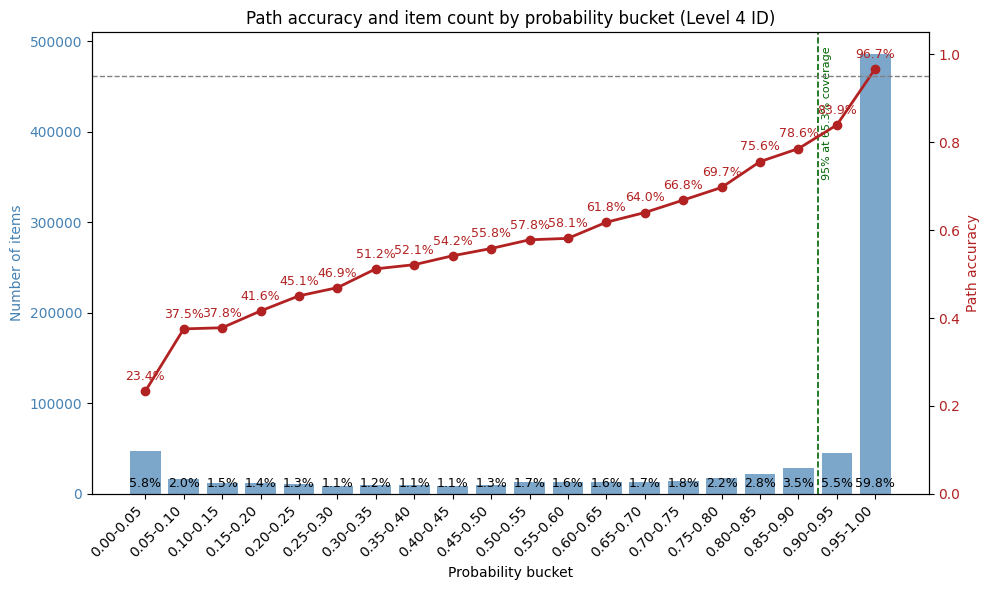

In [0]:
# Item count and accuracy by confidence bucket (deepest level)
fig = evaluation.plot_accuracy_by_bucket(pred, LEVEL_COLUMNS, width=BUCKET_WIDTH, depth=len(LEVEL_COLUMNS),
                                         target_accuracy=TARGET_ACCURACY)
evaluation.save_figure(fig, PLOT_DIR, f"accuracy_by_bucket_L{len(LEVEL_COLUMNS)}_w{BUCKET_WIDTH}", tracker)

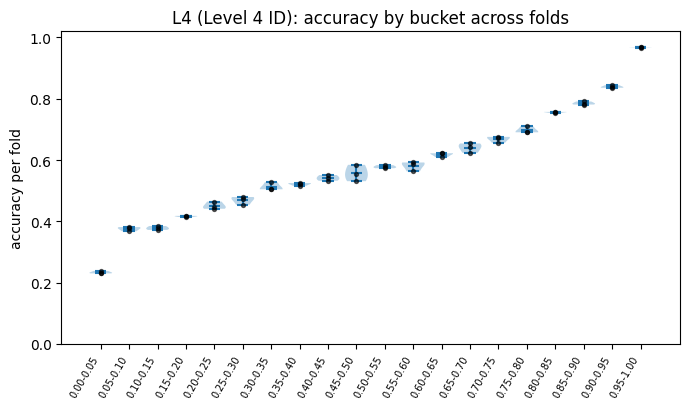

In [0]:
# Violin plot of cross-validation results by confidence bucket (deepest level)
fig = evaluation.plot_violins(pred, LEVEL_COLUMNS, width=BUCKET_WIDTH, depth=len(LEVEL_COLUMNS), split_col=SPLIT_COL)
evaluation.save_figure(fig, PLOT_DIR, f"violins_L{len(LEVEL_COLUMNS)}_w{BUCKET_WIDTH}", tracker)

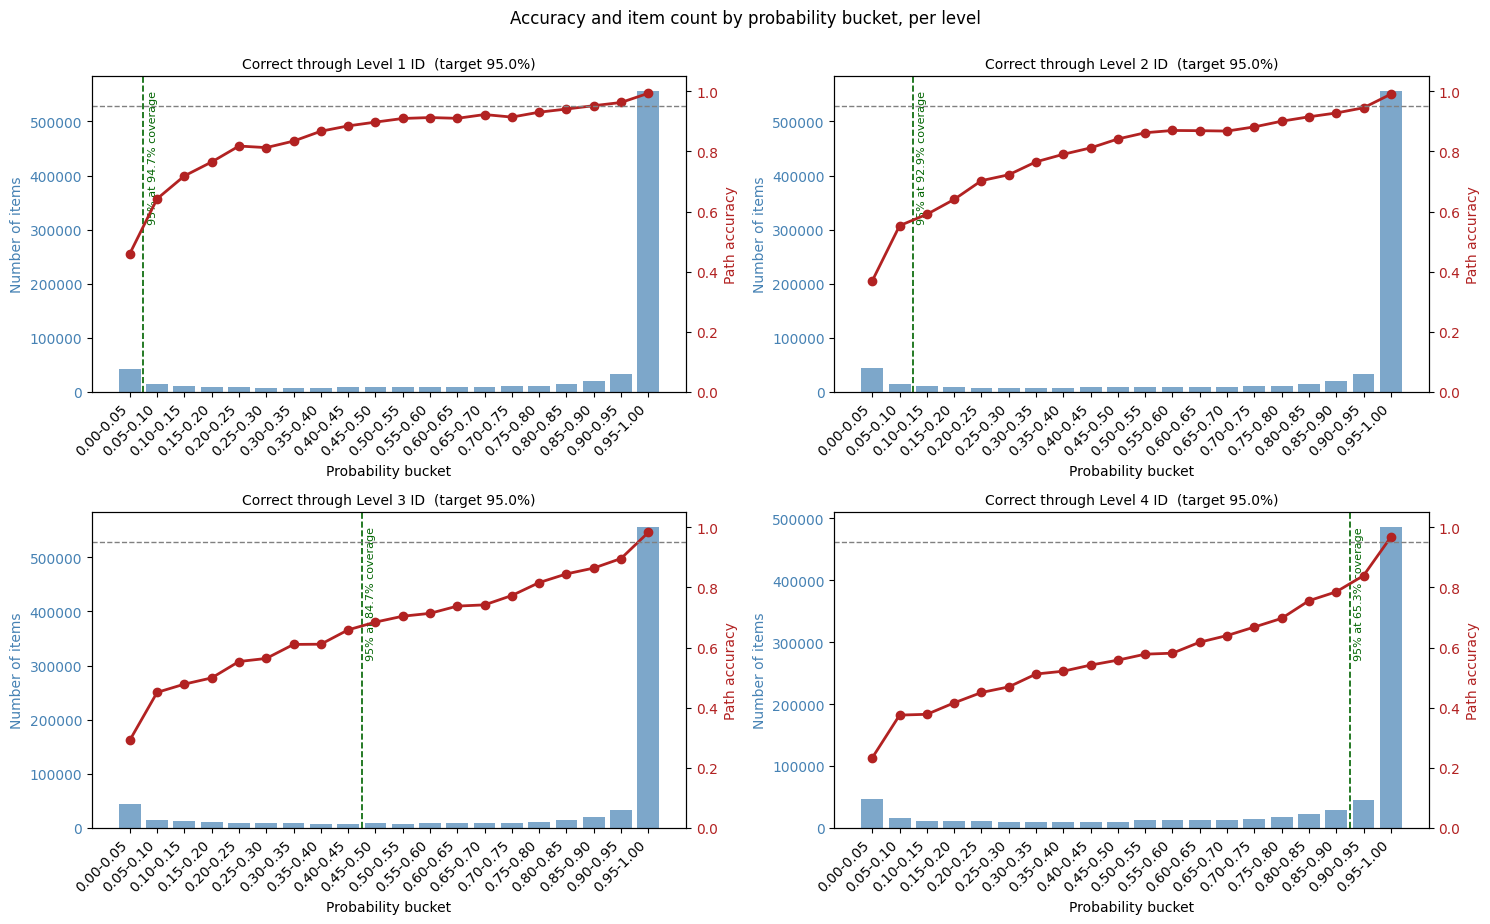

In [0]:
# Item count and accuracy by confidence bucket, by category level
fig = evaluation.plot_accuracy_by_bucket(pred, LEVEL_COLUMNS, width=BUCKET_WIDTH, target_accuracy=TARGET_ACCURACY)
evaluation.save_figure(fig, PLOT_DIR, f"accuracy_by_bucket_by_level_w{BUCKET_WIDTH}", tracker)

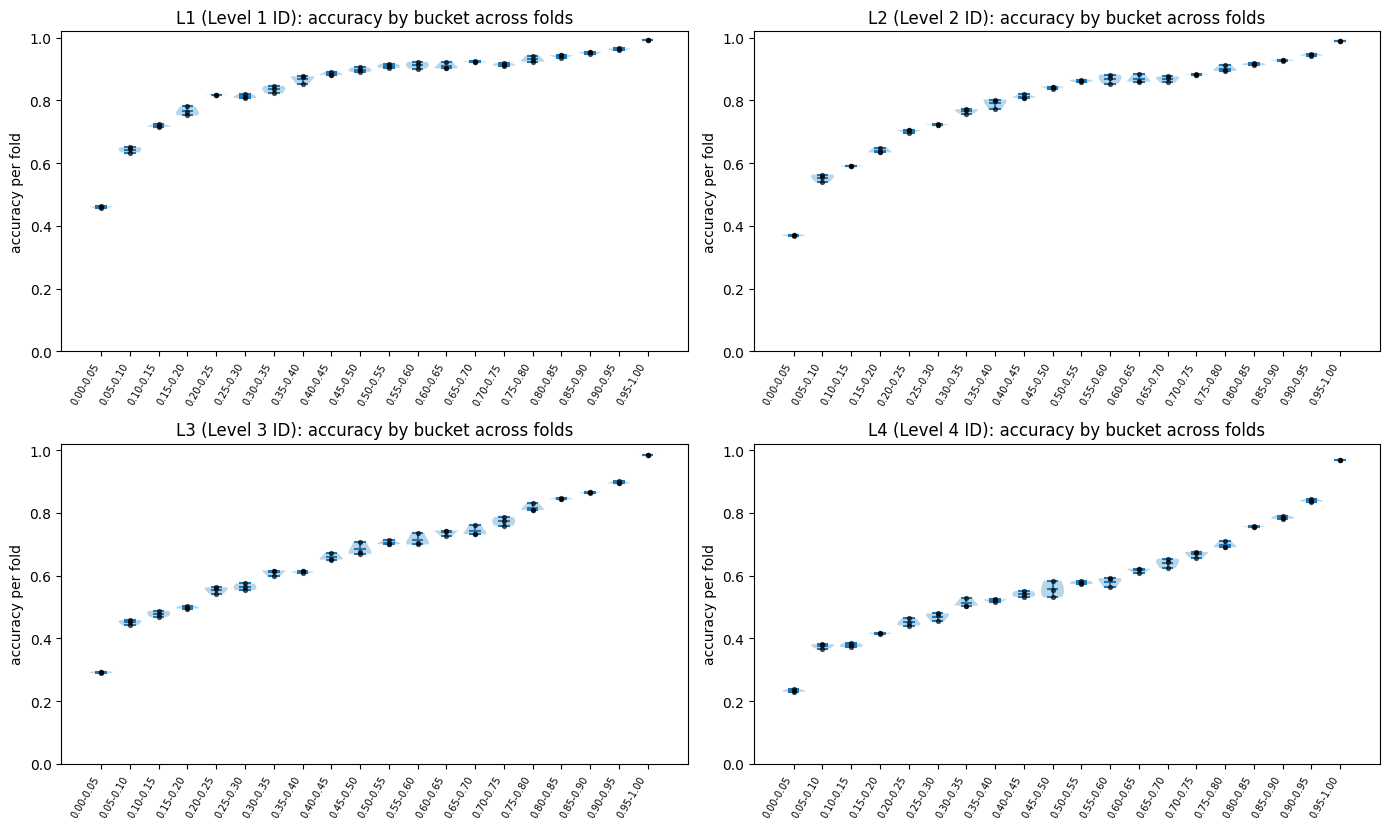

In [0]:
# Violin plots of cross-validation results by confidence bucket, by category level
fig = evaluation.plot_violins(pred, LEVEL_COLUMNS, width=BUCKET_WIDTH, split_col=SPLIT_COL)
evaluation.save_figure(fig, PLOT_DIR, f"violins_by_level_w{BUCKET_WIDTH}", tracker)

In [0]:
tracker.end()

[mlflow] run ended
